In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
users = pd.read_csv(
    "users.dat",
    sep="::",
    engine="python",
    names=["UserID", "Gender", "Age", "Occupation", "Zip_Code"],
    encoding="latin-1"
)

ratings = pd.read_csv(
    "ratings.dat",
    sep="::",
    engine="python",
    names=["UserID", "MovieID", "Rating", "Timestamp"],
    encoding="latin-1"
)

movies = pd.read_csv(
    "movies.dat",
    sep="::",
    engine="python",
    names=["MovieID", "Movie_Title", "Genres"],
    encoding="latin-1"
)

print("Users shape:", users.shape)
print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

Users shape: (6040, 5)
Ratings shape: (1000209, 4)
Movies shape: (3883, 3)


In [3]:
# Select ratings that indicate positive user preference
positive_ratings = ratings[
    ratings["Rating"] >= 4
]

# Count positive ratings for each user
user_positive_counts = (
    positive_ratings
    .groupby("UserID")
    .size()
)

# Keep users with at least 20 positive ratings
evaluation_users = user_positive_counts[
    user_positive_counts >= 20
].index

# Use the first 100 users for evaluation
evaluation_users = evaluation_users[:100]

print(
    "Users with at least 20 positive ratings:",
    len(user_positive_counts[user_positive_counts >= 20])
)

print(
    "Users selected for evaluation:",
    len(evaluation_users)
)

Users with at least 20 positive ratings: 5180
Users selected for evaluation: 100


In [4]:
# Create a copy of the complete ratings data
train_ratings = ratings.copy()

# Store the movies hidden for each user
test_movies = {}

# Make the split reproducible
np.random.seed(42)

for user_id in evaluation_users:

    # Get movies rated 4 or 5 by this user
    user_positive = ratings[
        (ratings["UserID"] == user_id) &
        (ratings["Rating"] >= 4)
    ]

    # Select 20% of positive ratings for testing
    n_test = max(
        1,
        int(len(user_positive) * 0.20)
    )

    selected_test_movies = np.random.choice(
        user_positive["MovieID"].values,
        size=n_test,
        replace=False
    )

    # Store hidden movies
    test_movies[user_id] = set(
        selected_test_movies
    )

    # Remove hidden movies from training data
    train_ratings = train_ratings[
        ~(
            (train_ratings["UserID"] == user_id) &
            (train_ratings["MovieID"].isin(
                selected_test_movies
            ))
        )
    ]

print("Original ratings:", len(ratings))
print("Training ratings:", len(train_ratings))
print("Hidden test movies:", sum(
    len(movies) for movies in test_movies.values()
))

Original ratings: 1000209
Training ratings: 998557
Hidden test movies: 1652


In [5]:
train_user_movie_matrix = train_ratings.pivot_table(
    index="UserID",
    columns="MovieID",
    values="Rating"
)

# Fill unrated movies with 0
train_user_movie_matrix = train_user_movie_matrix.fillna(0)

print(
    "Training matrix shape:",
    train_user_movie_matrix.shape
)

print(
    "Number of non-zero ratings:",
    (train_user_movie_matrix.values != 0).sum()
)

Training matrix shape: (6040, 3706)
Number of non-zero ratings: 998557


In [6]:
train_sparse_matrix = csr_matrix(
    train_user_movie_matrix.values
)

print("Sparse matrix shape:", train_sparse_matrix.shape)
print("Non-zero values:", train_sparse_matrix.nnz)

Sparse matrix shape: (6040, 3706)
Non-zero values: 998557


In [7]:
def recommend_baseline(
    user_id,
    num_recommendations=10,
    num_similar_users=20
):
    
    # Get the target user's row index
    user_index = train_user_movie_matrix.index.get_loc(
        user_id
    )

    # Calculate similarity between target user
    # and all other users
    similarities = cosine_similarity(
        train_sparse_matrix[user_index],
        train_sparse_matrix
    ).flatten()

    # Exclude the target user
    similarities[user_index] = -1

    # Select the most similar users
    similar_indices = np.argsort(
        similarities
    )[::-1][:num_similar_users]

    similar_scores = similarities[
        similar_indices
    ]

    # Get ratings of similar users
    similar_ratings = train_sparse_matrix[
        similar_indices
    ]

    # Calculate weighted recommendation scores
    weighted_scores = (
        similar_scores @ similar_ratings
    )

    weighted_scores = np.asarray(
        weighted_scores
    ).ravel()

    # Get movies already rated by the target user
    user_ratings = (
        train_sparse_matrix[user_index]
        .toarray()
        .ravel()
    )

    # Do not recommend movies already rated
    weighted_scores[user_ratings > 0] = -1

    # Select top movies
    recommended_indices = np.argsort(
        weighted_scores
    )[::-1][:num_recommendations]

    # Convert matrix indices to MovieIDs
    recommended_movie_ids = (
        train_user_movie_matrix.columns[
            recommended_indices
        ]
    )

    return recommended_movie_ids

In [8]:
def evaluate_model(
    recommendation_function,
    evaluation_users,
    k=10
):
    
    precisions = []
    recalls = []

    for user_id in evaluation_users:

        # Generate recommendations
        recommendations = recommendation_function(
            user_id,
            num_recommendations=k,
            num_similar_users=20
        )

        recommendations = set(
            recommendations
        )

        # Movies hidden from this user
        actual_movies = test_movies.get(
            user_id,
            set()
        )

        if len(actual_movies) == 0:
            continue

        # Movies that were both recommended
        # and actually hidden from the user
        relevant_movies = (
            recommendations & actual_movies
        )

        # Precision@K
        precision = (
            len(relevant_movies) / k
        )

        # Recall@K
        recall = (
            len(relevant_movies) /
            len(actual_movies)
        )

        precisions.append(precision)
        recalls.append(recall)

    return {
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls)
    }

In [9]:
baseline_results = evaluate_model(
    recommend_baseline,
    evaluation_users,
    k=10
)

print("Baseline Collaborative Filtering")
print("--------------------------------")
print(
    "Precision@10:",
    round(baseline_results["Precision@10"], 4)
)

print(
    "Recall@10:",
    round(baseline_results["Recall@10"], 4)
)

Baseline Collaborative Filtering
--------------------------------
Precision@10: 0.305
Recall@10: 0.2395


In [10]:
evaluation_kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

evaluation_clusters = evaluation_kmeans.fit_predict(
    train_sparse_matrix
)

evaluation_cluster_data = pd.DataFrame({
    "UserID": train_user_movie_matrix.index,
    "Cluster": evaluation_clusters
})

print("K-Means training completed.")
print("Number of clusters:", evaluation_cluster_data["Cluster"].nunique())
print("\nUsers per cluster:")
print(evaluation_cluster_data["Cluster"].value_counts().sort_index())

K-Means training completed.
Number of clusters: 5

Users per cluster:
Cluster
0     187
1    3398
2     738
3    1219
4     498
Name: count, dtype: int64


In [11]:
def recommend_clustered(
    user_id,
    num_recommendations=10,
    num_similar_users=20
):
    user_index = train_user_movie_matrix.index.get_loc(user_id)

    # Find the cluster of the target user
    user_cluster = evaluation_clusters[user_index]

    # Get users belonging to the same cluster
    cluster_indices = np.where(
        evaluation_clusters == user_cluster
    )[0]

    # Calculate similarity only within the same cluster
    cluster_matrix = train_sparse_matrix[cluster_indices]

    similarities = cosine_similarity(
        train_sparse_matrix[user_index],
        cluster_matrix
    ).flatten()

    # Remove the target user from the similarity search
    target_position = np.where(
        cluster_indices == user_index
    )[0][0]

    similarities[target_position] = -1

    # Select the most similar users
    actual_num_users = min(
        num_similar_users,
        len(cluster_indices) - 1
    )

    similar_positions = np.argsort(
        similarities
    )[::-1][:actual_num_users]

    similar_indices = cluster_indices[similar_positions]

    similar_scores = similarities[similar_positions]
    similar_ratings = train_sparse_matrix[similar_indices]

    # Weighted recommendation scores
    weighted_scores = similar_scores @ similar_ratings
    weighted_scores = np.asarray(
        weighted_scores
    ).ravel()

    # Do not recommend movies already rated by the user
    user_ratings = train_sparse_matrix[user_index].toarray().ravel()
    weighted_scores[user_ratings > 0] = -1

    # Select top recommendations
    recommended_indices = np.argsort(
        weighted_scores
    )[::-1][:num_recommendations]

    recommended_movie_ids = (
        train_user_movie_matrix
        .columns[recommended_indices]
    )

    return recommended_movie_ids

In [12]:
clustered_test = recommend_clustered(
    user_id=1,
    num_recommendations=10,
    num_similar_users=20
)

print("Clustered recommendations for User 1:")
print(clustered_test)

Clustered recommendations for User 1:
Index([588, 2081, 2085, 364, 596, 2096, 2078, 1196, 2080, 1907], dtype='int64', name='MovieID')


In [13]:
clustered_results = evaluate_model(
    recommend_clustered,
    evaluation_users,
    k=10
)

print("K-Means + Collaborative Filtering")
print("----------------------------------")

print(
    "Precision@10:",
    round(clustered_results["Precision@10"], 4)
)

print(
    "Recall@10:",
    round(clustered_results["Recall@10"], 4)
)

K-Means + Collaborative Filtering
----------------------------------
Precision@10: 0.299
Recall@10: 0.2352


In [14]:
comparison = pd.DataFrame({
    "Model": [
        "Collaborative Filtering + Cosine Similarity",
        "K-Means + Collaborative Filtering"
    ],
    "Precision@10": [
        baseline_results["Precision@10"],
        clustered_results["Precision@10"]
    ],
    "Recall@10": [
        baseline_results["Recall@10"],
        clustered_results["Recall@10"]
    ]
})

comparison["Precision@10"] = comparison["Precision@10"].round(4)
comparison["Recall@10"] = comparison["Recall@10"].round(4)

comparison

,Model,Precision@10,Recall@10
0,Collaborative Filtering + Cosine Similarity,0.305,0.2395
1,K-Means + Collaborative Filtering,0.299,0.2352


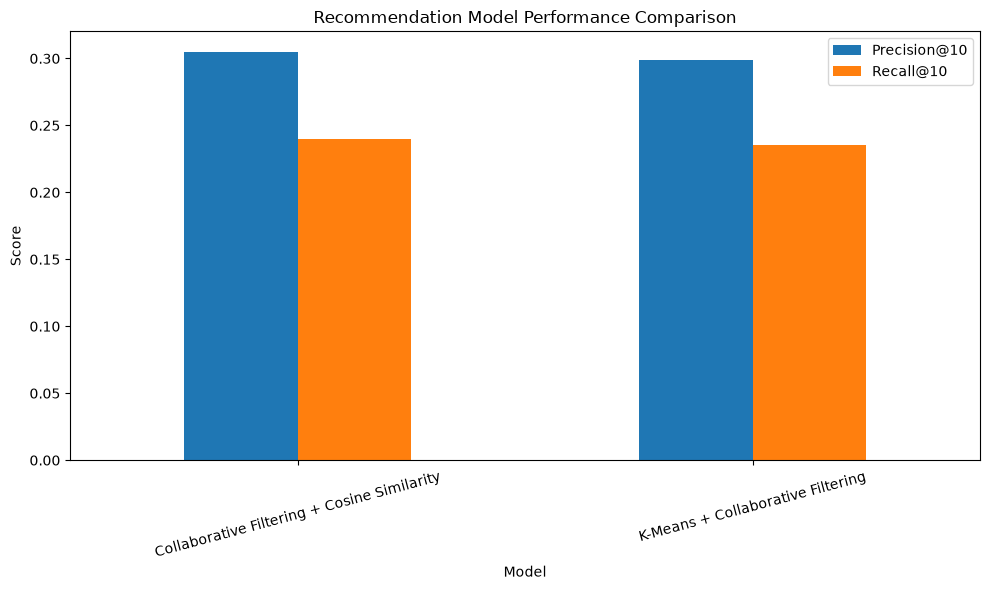

In [15]:
comparison.set_index("Model")[["Precision@10", "Recall@10"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Recommendation Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
similar_user_values = [5, 10, 20, 30, 50]

tuning_results = []

for n_users in similar_user_values:

    def recommend_tuned(user_id, num_recommendations=10, num_similar_users=n_users):
        user_index = train_user_movie_matrix.index.get_loc(user_id)

        similarities = cosine_similarity(
            train_sparse_matrix[user_index],
            train_sparse_matrix
        ).flatten()

        similarities[user_index] = -1

        actual_num_users = min(
            num_similar_users,
            len(train_user_movie_matrix) - 1
        )

        similar_indices = np.argsort(
            similarities
        )[::-1][:actual_num_users]

        similar_scores = similarities[similar_indices]
        similar_ratings = train_sparse_matrix[similar_indices]

        weighted_scores = similar_scores @ similar_ratings
        weighted_scores = np.asarray(weighted_scores).ravel()

        user_ratings = train_sparse_matrix[user_index].toarray().ravel()
        weighted_scores[user_ratings > 0] = -1

        recommended_indices = np.argsort(
            weighted_scores
        )[::-1][:num_recommendations]

        return train_user_movie_matrix.columns[recommended_indices]

    results = evaluate_model(
        recommend_tuned,
        evaluation_users,
        k=10
    )

    tuning_results.append({
        "Similar Users": n_users,
        "Precision@10": results["Precision@10"],
        "Recall@10": results["Recall@10"]
    })

tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df["Precision@10"] = tuning_results_df["Precision@10"].round(4)
tuning_results_df["Recall@10"] = tuning_results_df["Recall@10"].round(4)

tuning_results_df

,Similar Users,Precision@10,Recall@10
0,5,0.305,0.2395
1,10,0.305,0.2395
2,20,0.305,0.2395
3,30,0.305,0.2395
4,50,0.305,0.2395


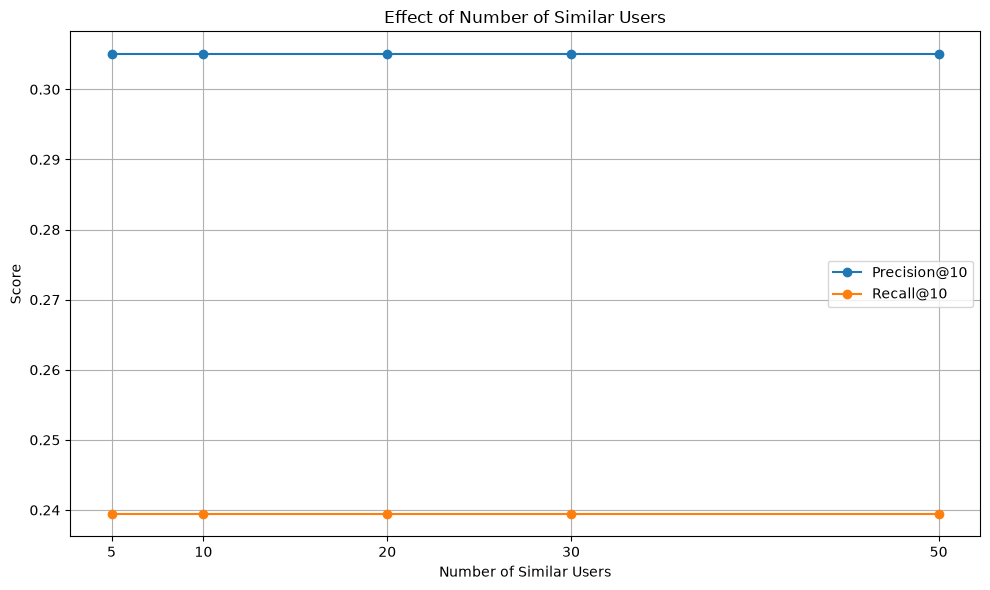

In [17]:
tuning_results_df.set_index("Similar Users")[[
    "Precision@10",
    "Recall@10"
]].plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.title("Effect of Number of Similar Users")
plt.xlabel("Number of Similar Users")
plt.ylabel("Score")
plt.xticks(similar_user_values)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
recommended_movie_ids = recommend_baseline(
    user_id=1,
    num_recommendations=10,
    num_similar_users=20
)

final_recommendations = movies[
    movies["MovieID"].isin(recommended_movie_ids)
][["MovieID", "Movie_Title", "Genres"]].copy()

recommendation_order = {
    movie_id: rank + 1
    for rank, movie_id in enumerate(recommended_movie_ids)
}

final_recommendations["Recommendation_Rank"] = (
    final_recommendations["MovieID"].map(recommendation_order)
)

final_recommendations = final_recommendations.sort_values(
    "Recommendation_Rank"
).reset_index(drop=True)

final_recommendations

,MovieID,Movie_Title,Genres,Recommendation_Rank
0,588,Aladdin (1992),Animation|Children's|Comedy|Musical,1
1,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,2
2,2081,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,3
3,364,"Lion King, The (1994)",Animation|Children's|Musical,4
4,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,5
5,1907,Mulan (1998),Animation|Children's,6
6,2078,"Jungle Book, The (1967)",Animation|Children's|Comedy|Musical,7
7,2858,American Beauty (1999),Comedy|Drama,8
8,1282,Fantasia (1940),Animation|Children's|Musical,9
9,2087,Peter Pan (1953),Animation|Children's|Fantasy|Musical,10


In [19]:
all_recommended_movies = set()

for user_id in evaluation_users:
    recommendations = recommend_baseline(
        user_id,
        num_recommendations=10,
        num_similar_users=20
    )
    
    all_recommended_movies.update(recommendations)

total_movies = len(train_user_movie_matrix.columns)
recommended_movies = len(all_recommended_movies)

catalog_coverage = recommended_movies / total_movies

print("Total movies in training data:", total_movies)
print("Unique movies recommended:", recommended_movies)
print("Catalog Coverage:", round(catalog_coverage, 4))
print("Catalog Coverage (%):", round(catalog_coverage * 100, 2), "%")

Total movies in training data: 3706
Unique movies recommended: 313
Catalog Coverage: 0.0845
Catalog Coverage (%): 8.45 %


# Evaluation Summary

The movie recommendation system was evaluated using a user-based collaborative filtering approach on the MovieLens 1M dataset.

For evaluation, 100 users were selected and 20% of their positive ratings (ratings >= 4) were hidden as test data. The remaining ratings were used to construct the training user-movie matrix.

## Results

| Model | Precision@10 | Recall@10 |
|---|---:|---:|
| Collaborative Filtering + Cosine Similarity | 0.3050 | 0.2395 |
| K-Means + Collaborative Filtering | 0.2990 | 0.2352 |

The baseline collaborative filtering model produced a Precision@10 of 0.3050 and Recall@10 of 0.2395. The K-Means-based approach produced slightly lower values of 0.2990 and 0.2352 respectively on the same evaluation set.

The number of similar users was varied between 5, 10, 20, 30, and 50. The measured Precision@10 and Recall@10 remained unchanged at 0.3050 and 0.2395 for all tested values.

The baseline model recommended 313 unique movies out of 3,706 movies available in the training interaction matrix, resulting in a catalog coverage of 8.45%.

## Conclusion

The evaluation demonstrates that the implemented user-based collaborative filtering model can generate personalized movie recommendations from user rating behavior. Cosine similarity was used to identify users with similar rating patterns, and ratings from these similar users were used to generate recommendations.

K-Means clustering was also evaluated as an auxiliary approach for restricting similarity calculations to users within the same cluster. On the selected evaluation set, this did not improve Precision@10 or Recall@10 compared with the baseline approach.